## 运行说明

本 notebook 是该分析的用户入口：先检查并生成所需 `logs/`，再读取结果、完成分析并把图片写入同名 `figures/` 目录。

- 默认 `FORCE_RECOMPUTE = False`：已有日志直接复用，缺失日志才计算。
- 若需要从数据重新计算本 notebook 依赖的日志，将下一单元中的开关改为 `True`。
- 耗时较长的计算保留在同目录、同主题的 `.py` 中；短计算直接写在本 notebook 中。


In [1]:
from pathlib import Path
import subprocess

PROJECT_ROOT = Path('..').resolve()
SCRIPT_DIR = PROJECT_ROOT / 'scripts'
PYTHON = PROJECT_ROOT / 'venv/bin/python'
FORCE_RECOMPUTE = False

def run_long_task(script_name, sentinel, *arguments):
    sentinel = PROJECT_ROOT / sentinel
    if FORCE_RECOMPUTE or not sentinel.exists():
        command = [str(PYTHON), str(SCRIPT_DIR / script_name), *map(str, arguments)]
        print('运行：', ' '.join(command))
        subprocess.run(command, cwd=PROJECT_ROOT, check=True)
    else:
        print('复用：', sentinel.relative_to(PROJECT_ROOT))

run_long_task('261027神经活动轨迹数据审计.py', 'logs/audit_data/initial/summary.json')
run_long_task('261027区域低秩算子扫描.py', 'logs/regional_lowrank_sweep/initial/rank_summary.csv')


复用： logs/audit_data/initial/summary.json
复用： logs/regional_lowrank_sweep/initial/rank_summary.csv


# Regional low-rank operator sweep

A full linear increment operator is truncated either directly or after preserving its diagonal self-feedback. Rank and ridge strength are selected/evaluated with chronological episode splits.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from yumeow_plot import get_fig

ROOT = Path('..').resolve()
RUN = ROOT / 'logs/regional_lowrank_sweep/initial'
OUT = ROOT / 'figures/261027区域低秩算子扫描'
OUT.mkdir(parents=True, exist_ok=True)
summary = pd.read_csv(RUN / 'rank_summary.csv')
summary

,state,structure,rank,alpha,validation_mse,dx_r2_flat,dx_r2_region_median,dx_corr_flat,rollout_r2_at_4s,rollout_corr_at_4s
0,Awake,pure_lowrank,1,1000.0,0.116135,0.030875,0.037747,0.177298,-0.806786,0.082933
1,Awake,pure_lowrank,2,1000.0,0.114396,0.042505,0.039586,0.207823,-0.703605,0.085890
2,Awake,pure_lowrank,3,1000.0,0.113714,0.046559,0.043921,0.218585,-0.665529,0.094505
3,Awake,pure_lowrank,5,1000.0,0.111937,0.057913,0.061748,0.245090,-0.592064,0.106141
4,Awake,pure_lowrank,8,1000.0,0.110665,0.067456,0.058175,0.264281,-0.360287,0.118711
5,Awake,pure_lowrank,12,1000.0,0.109924,0.074706,0.059797,0.276988,-0.297724,0.119868
6,Awake,pure_lowrank,25,100.0,0.109085,0.079942,0.070488,0.299447,-0.008627,0.150599
7,Awake,diagonal_plus_lowrank,1,1000.0,0.112770,0.053276,0.050216,0.242518,-0.202768,0.060710
8,Awake,diagonal_plus_lowrank,2,1000.0,0.111466,0.062286,0.063089,0.256590,-0.295811,0.067451
9,Awake,diagonal_plus_lowrank,3,1000.0,0.110954,0.063181,0.059796,0.261029,-0.339114,0.102162


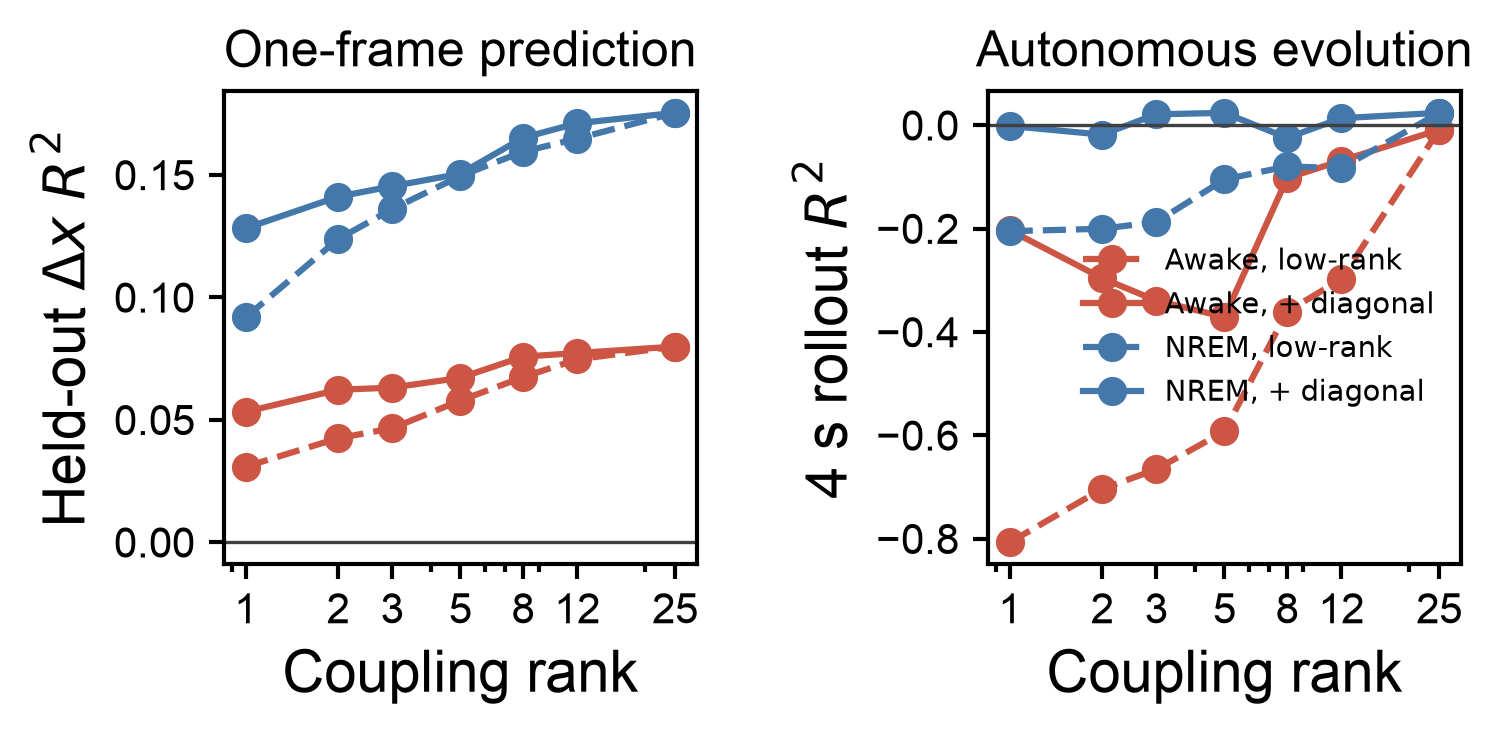

In [3]:
colors = {'Awake': '#cc5544', 'NREM': '#4477aa'}
styles = {'pure_lowrank': '--', 'diagonal_plus_lowrank': '-'}
names = {'pure_lowrank': 'low-rank', 'diagonal_plus_lowrank': '+ diagonal'}
fig, axes = get_fig(RN=1, CN=2, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(axes)
for panel, (metric, ylabel, title) in enumerate([('dx_r2_flat', r'Held-out $\Delta x$ $R^2$', 'One-frame prediction'), ('rollout_r2_at_4s', r'4 s rollout $R^2$', 'Autonomous evolution')]):
    ax = next(ax_loader)
    for state in ['Awake', 'NREM']:
        for structure in styles:
            part = summary[(summary.state == state) & (summary.structure == structure)]
            ax.plot(part['rank'], part[metric], marker='o', color=colors[state], ls=styles[structure], label=f'{state}, {names[structure]}')
    ax.axhline(0, color='0.25', lw=.8)
    ax.set(xlabel='Coupling rank', ylabel=ylabel, title=title, xscale='log')
    ax.set_xticks([1, 2, 3, 5, 8, 12, 25], [1, 2, 3, 5, 8, 12, 25])
    if panel == 1:
        ax.legend(frameon=False, fontsize=7, loc='center right')
fig.savefig(OUT / 'lowrank_sweep.png', transparent=True)
fig.savefig(OUT / 'lowrank_sweep.svg', transparent=True)
fig.savefig(OUT / 'lowrank_sweep.pdf', transparent=True)
plt.show()

## Interpretation

Coefficient energy alone is not a safe rank criterion. Pure low-rank truncation retains much of one-step predictability but damages 4 s autonomous evolution. Keeping each region's diagonal self-feedback before compressing off-diagonal coupling substantially repairs stability. In NREM, diagonal plus rank 3–5 reaches one-frame increment R² of about 0.145–0.151 and 4 s rollout R² of about 0.021–0.024, versus 0.175 and 0.024 for the full rank-25 operator.

Thus a compact equation of the form `dx/dt = D_s x + U_s V_s^T x` is plausible for NREM, with `D_s` playing a stabilizing local role. Awake needs more residual rank for comparable held-out performance, and even the full linear model has little useful 4 s residual prediction.